# Akciğer Nodülü Malignite Sınıflandırması — 2. Bölütleme v2, hibrit model, test ve demo

Önce 1. defterin Drive'a kaydettiği dosyalar gerekir. İlk hücre veriyi ve CNN modellerini yükleyip Gradio arayüzünü başlatır; sonraki hücreler bölütleme v2'yi, model karşılaştırmasını ve son test ölçümünü içerir.

## Demo (ilk sürüm) — Gradio arayüzü ve kendini doğrulama
Demo, kayıtlı test tahminlerini yeniden üreterek raporlanan modelin aynısı olduğunu kontrol eder (ortalama fark 0,00023).

In [1]:
!pip -q install gradio

import glob, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, matplotlib.pyplot as plt, gradio as gr
from scipy import ndimage
from skimage.filters import threshold_otsu
from skimage.morphology import disk
from skimage.segmentation import watershed
from sklearn.ensemble import RandomForestClassifier
from google.colab import drive
drive.mount("/content/drive")
KOK = "/content/drive/MyDrive/akciger_nodul_LUNA25"
DEV = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- 1) Veri ----------
X_p = np.load(f"{KOK}/X_pencere.npy", mmap_mode="r")   # CNN girdisi (HU pencereli)
X_c = np.load(f"{KOK}/X_clahe.npy",   mmap_mode="r")   # görselleştirme
X_m = np.load(f"{KOK}/X_medyan.npy",  mmap_mode="r")   # bölütleme girdisi
df  = pd.read_csv(f"{KOK}/etiketler_bolunmus.csv")
oz  = pd.read_csv(f"{KOK}/ozellikler.csv")
print("etiket sütunları:", df.columns.tolist())
print("özellik sütunları:", oz.columns.tolist())

def sutun_bul(tablo, adaylar):
    for c in adaylar:
        if c in tablo.columns: return c
    raise ValueError(f"Bu sütunlardan hiçbiri yok: {adaylar} -> çıktıyı bana gönder")
ETIKET = sutun_bul(df, ["label", "Label", "malignancy", "etiket"])
assert len(oz) == len(df) == len(X_p), "satır sayıları uyuşmuyor"

y = df[ETIKET].values.astype(int)
test_idx  = np.where(df["fold"].values == -1)[0]
egit_idx  = np.where(df["fold"].values != -1)[0]

# ---------- 2) Klasik model: sadece eğitim katlarıyla ----------
meta = {"label", "etiket", "fold", "malignancy"}
OZ = [c for c in oz.select_dtypes("number").columns
      if c.lower() not in meta and "id" not in c.lower()]
print("RF özellikleri:", OZ)
medyanlar = oz.loc[egit_idx, OZ].median()
Z = oz[OZ].fillna(medyanlar).values
rf = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1,
                            class_weight="balanced").fit(Z[egit_idx], y[egit_idx])

# ---------- 3) CNN: 5 kat modeli ----------
def model_kur():
    m = torchvision.models.resnet18(weights=None)
    m.fc = nn.Linear(512, 1)
    return m
MODELLER = []
for yol in sorted(glob.glob(f"{KOK}/modeller/pencere_kat*.pt")):
    m = model_kur()
    sd = torch.load(yol, map_location="cpu")
    m.load_state_dict({k: v.float() for k, v in sd.items()})
    MODELLER.append(m.to(DEV).eval())
print("yüklenen model:", len(MODELLER))

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEV)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEV)
def hazirla(idx, norm):
    x = torch.from_numpy(np.asarray(X_p[idx], dtype=np.float32) / 255.).to(DEV)
    if x.ndim == 3: x = x[None]
    x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD if norm else x

@torch.no_grad()
def cnn_olasilik(x):
    return np.mean([torch.sigmoid(m(x)).squeeze(1).cpu().numpy() for m in MODELLER], axis=0)

# Kendini kontrol: kayıtlı test tahminleriyle karşılaştır
ref = np.load(f"{KOK}/test_tahmin_cnn.npy").astype(float)
if ref.ndim == 2:
    ref = ref.mean(axis=1) if ref.shape[0] == len(test_idx) else ref.mean(axis=0)
if ref.min() < 0 or ref.max() > 1: ref = 1 / (1 + np.exp(-ref))
ornek = test_idx[:32]
fark = {n: np.abs(cnn_olasilik(hazirla(ornek, n)) - ref[:32]).mean() for n in (True, False)}
NORM = min(fark, key=fark.get)
print(f"kontrol -> ImageNet norm={NORM}, ortalama fark={fark[NORM]:.4f} (0.01 altı = birebir aynı model)")

# ---------- 4) Grad-CAM ----------
def gradcam(x):
    haritalar = []
    for m in MODELLER:
        akt = {}
        h = m.layer4[-1].register_forward_hook(lambda mod, i, o: akt.__setitem__("a", o))
        with torch.enable_grad():
            cikti = m(x)
            g = torch.autograd.grad(cikti.sum(), akt["a"])[0]
        h.remove()
        w = g.mean(dim=(2, 3), keepdim=True)              # kanal ağırlıkları
        cam = F.relu((w * akt["a"]).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=128, mode="bilinear", align_corners=False)[0, 0]
        haritalar.append((cam / (cam.max() + 1e-8)).cpu().numpy())
    return np.mean(haritalar, axis=0)

# ---------- 5) Klasik bölütleme (projedekiyle aynı adımlar) ----------
def morf(A, islem, r):
    p = r + 1
    return islem(np.pad(A, p, mode="edge"), structure=disk(r))[p:-p, p:-p]
KENAR = np.zeros((128, 128), bool)
KENAR[:2, :] = KENAR[-2:, :] = KENAR[:, :2] = KENAR[:, -2:] = True

def bolutle_adimlar(k):
    esik = threshold_otsu(k[32:96, 32:96])
    ikili = k > esik
    acik = morf(ikili, ndimage.binary_opening, 1)
    kapali = ndimage.binary_fill_holes(morf(acik, ndimage.binary_closing, 2))
    maske = np.zeros_like(kapali)
    if kapali.any():
        isaret = np.zeros(k.shape, int)
        isaret[KENAR & kapali] = 2
        yy, xx = np.nonzero(kapali)
        j = np.argmin((yy - 64) ** 2 + (xx - 64) ** 2)
        isaret[yy[j], xx[j]] = 1
        maske = watershed(-ndimage.distance_transform_edt(kapali), isaret, mask=kapali) == 1
    return ikili, kapali, maske

# ---------- 6) Analiz + arayüz ----------
def analiz(sira):
    idx = int(test_idx[int(sira)])
    x = hazirla(idx, NORM)
    p_cnn = float(cnn_olasilik(x)[0])
    p_rf = float(rf.predict_proba(Z[idx:idx + 1])[0, 1])
    cam = gradcam(x)
    ham, cl, med = X_p[idx, 1], X_c[idx, 1], X_m[idx, 1]
    ikili, kapali, maske = bolutle_adimlar(med)

    fig, ax = plt.subplots(2, 4, figsize=(16, 8))
    paneller = [(ham, "1. HU pencereleme"), (cl, "2. CLAHE"), (med, "3. Medyan filtre"),
                (ikili, "4. Otsu eşikleme"), (kapali, "5. Açma + kapama + doldurma")]
    for a, (im, baslik) in zip(ax.flat, paneller):
        a.imshow(im, cmap="gray"); a.set_title(baslik)
    ax[1, 1].imshow(ham, cmap="gray"); ax[1, 1].contour(maske, colors="lime", linewidths=1.5)
    ax[1, 1].set_title("6. Watershed maskesi")
    ax[1, 2].imshow(ham, cmap="gray"); ax[1, 2].imshow(cam, cmap="jet", alpha=0.45)
    ax[1, 2].set_title("7. Grad-CAM (CNN nereye baktı)")
    ax[1, 3].hist(np.ravel(ham), 64, alpha=.6, label="pencere")
    ax[1, 3].hist(np.ravel(cl), 64, alpha=.6, label="CLAHE")
    ax[1, 3].legend(); ax[1, 3].set_title("8. Histogram")
    for a in list(ax.flat)[:7]: a.axis("off")
    fig.tight_layout(); plt.close(fig)

    gercek = "MALİGN" if y[idx] == 1 else "benign"
    secili = ", ".join(f"{c}={oz.at[idx, c]:.2f}" for c in OZ[:6])
    md = (f"### Test nodülü #{int(sira)} (satır {idx})\n"
          f"**Gerçek etiket:** {gercek}\n\n"
          f"| Yöntem | Malignite olasılığı |\n|---|---|\n"
          f"| Klasik (bölütleme + özellik + RF) | {p_rf:.3f} |\n"
          f"| CNN (ResNet-18, 5 model ortalaması) | {p_cnn:.3f} |\n\n"
          f"**Özelliklerden bazıları:** {secili}")
    return fig, md

rng = np.random.default_rng()
def rastgele(sinif):
    adaylar = np.where(y[test_idx] == sinif)[0]
    return int(rng.choice(adaylar))

with gr.Blocks(title="Akciğer Nodülü Malignite Analizi") as demo:
    gr.Markdown("# BT Görüntülerinde Akciğer Nodülü Malignite Analizi\n"
                "LUNA25 test seti · klasik görüntü işleme ve CNN karşılaştırması")
    with gr.Row():
        sira = gr.Slider(0, len(test_idx) - 1, step=1, value=0, label="Test nodülü sırası")
        b_m = gr.Button("Rastgele malign")
        b_b = gr.Button("Rastgele benign")
        b_a = gr.Button("Analiz et", variant="primary")
    md = gr.Markdown()
    cizim = gr.Plot()
    b_a.click(analiz, sira, [cizim, md])
    b_m.click(lambda: rastgele(1), None, sira).then(analiz, sira, [cizim, md])
    b_b.click(lambda: rastgele(0), None, sira).then(analiz, sira, [cizim, md])

demo.launch(share=True, debug=False)

Mounted at /content/drive
etiket sütunları: ['PatientID', 'SeriesInstanceUID', 'StudyDate', 'CoordX', 'CoordY', 'CoordZ', 'LesionID', 'AnnotationID', 'NoduleID', 'label', 'Age_at_StudyDate', 'Gender', 'fold']
özellik sütunları: ['alan_mm2', 'esdeger_cap_mm', 'dairesellik', 'doluluk', 'eksantriklik', 'ort_hu', 'std_hu', 'kalsifikasyon_orani', 'kenar_gradyani']
RF özellikleri: ['alan_mm2', 'esdeger_cap_mm', 'dairesellik', 'doluluk', 'eksantriklik', 'ort_hu', 'std_hu', 'kalsifikasyon_orani', 'kenar_gradyani']
yüklenen model: 5
kontrol -> ImageNet norm=True, ortalama fark=0.0002 (0.01 altı = birebir aynı model)
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8bf85e31b83f1e8a38.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingfa

## Adım 18a — Bölütleme kalite sayımı (ilk, kaba ölçüt)
Not: dairesellik > 1 ölçütü küçük nesnelerde ölçüm sapması verdiği için geçersiz çıktı; sonraki hücrede gözle sayım yapıldı.

In [2]:
cap = oz["esdeger_cap_mm"]; dai = oz["dairesellik"]
kotu = (cap < 3) | (dai > 1)          # 3 mm altı ya da imkânsız dairesellik = başarısız maske
print(f"Toplam: {len(oz)}  |  başarısız maske: {kotu.sum()} (%{100*kotu.mean():.1f})")
print(f"  çap < 3 mm: {(cap < 3).sum()}   dairesellik > 1: {(dai > 1).sum()}")
for s, ad in [(1, "malign"), (0, "benign")]:
    print(f"  {ad}: %{100*kotu[y == s].mean():.1f}")
print("Başarısız test örnekleri (demoda kaçınmak için):",
      [int(np.where(test_idx == i)[0][0]) for i in test_idx if kotu[i]][:15])

Toplam: 6163  |  başarısız maske: 3795 (%61.6)
  çap < 3 mm: 1796   dairesellik > 1: 3777
  malign: %25.0
  benign: %65.2
Başarısız test örnekleri (demoda kaçınmak için): [1, 9, 10, 15, 19, 29, 31, 33, 34, 36, 37, 38, 39, 40, 41]


## Adım 18a — Gözle kontrol için 24 rastgele nodül (tohum 0)

çap<3 mm: 1796 (%29.1) | malign %15.1, benign %30.5
çap>=3 mm olanlarda dairesellik:
count    4367.00
mean        0.92
std         0.27
min         0.13
10%         0.50
50%         0.97
90%         1.22
max         1.61
Name: dairesellik, dtype: float64


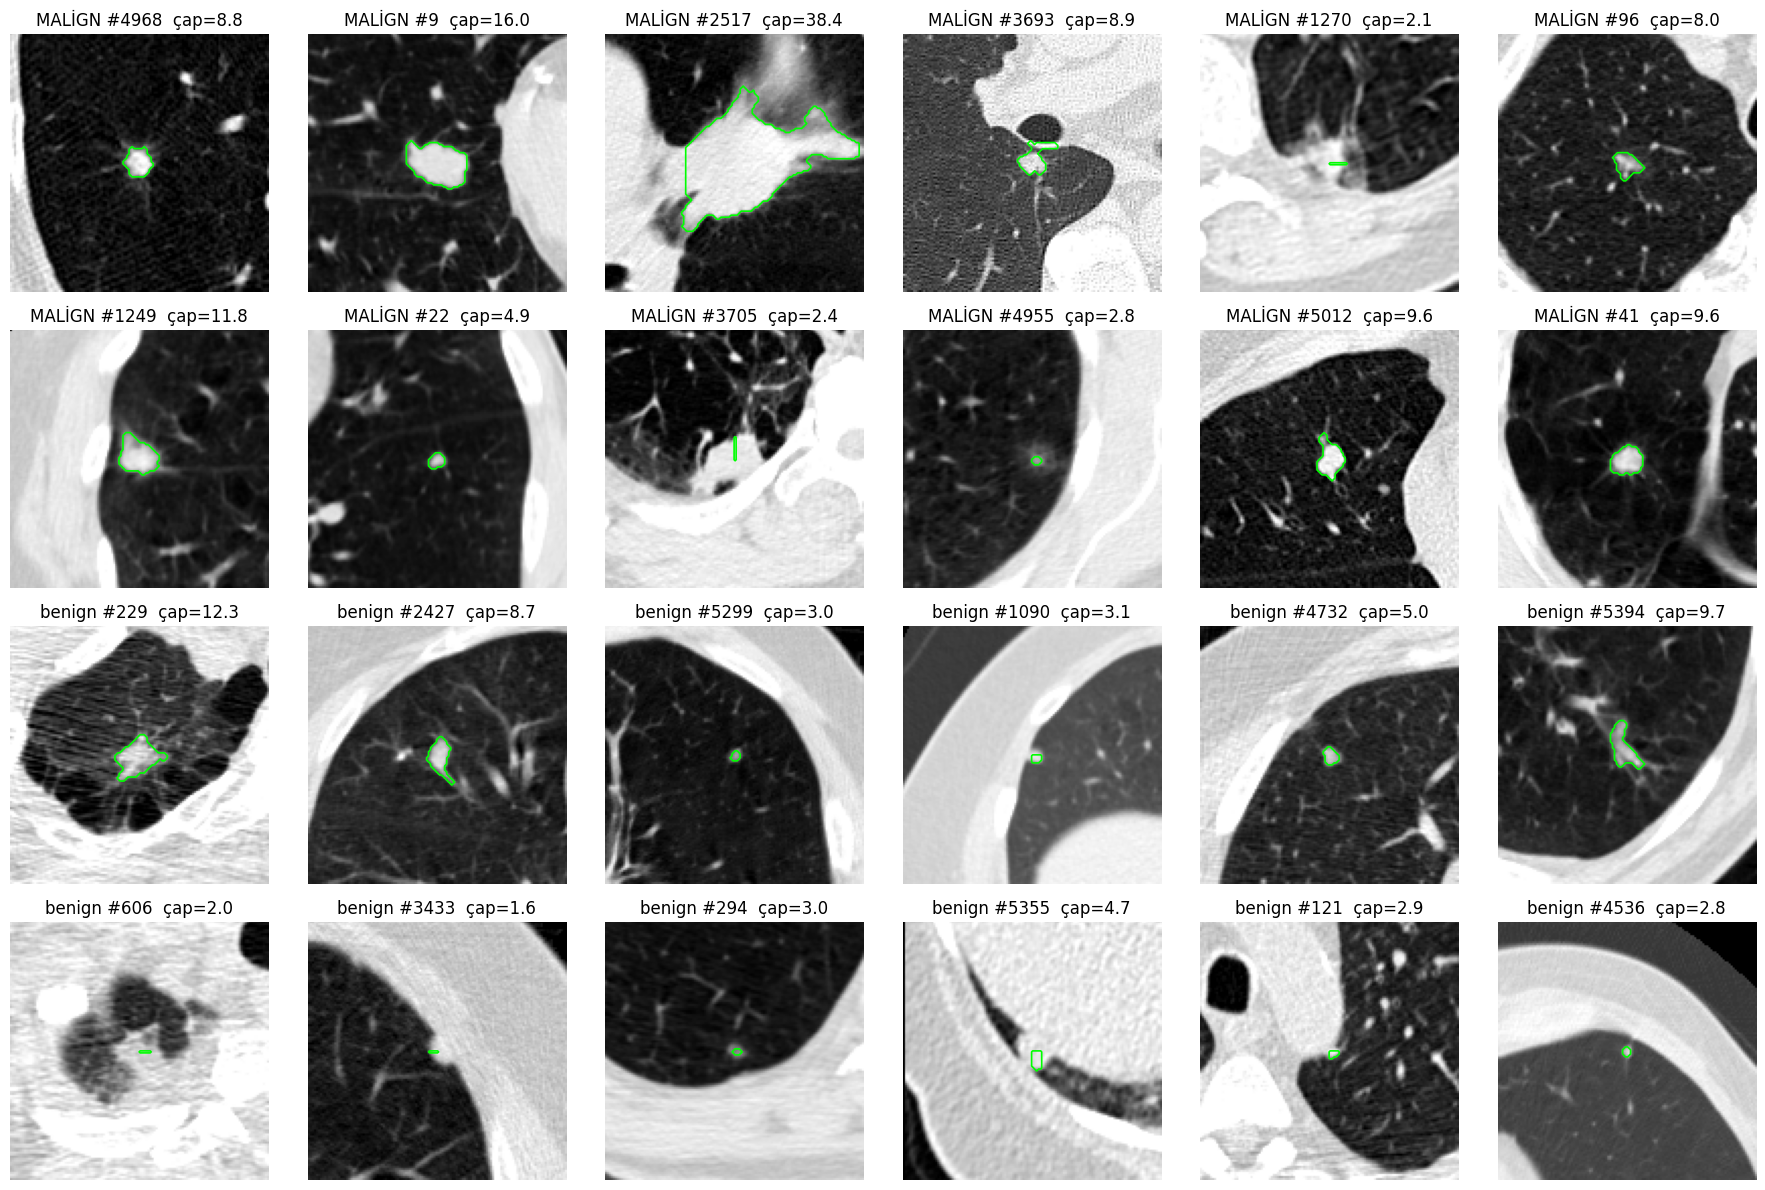

In [3]:
cap = oz["esdeger_cap_mm"]; dai = oz["dairesellik"]
kucuk = cap < 3
print(f"çap<3 mm: {kucuk.sum()} (%{100*kucuk.mean():.1f}) | "
      f"malign %{100*kucuk[y==1].mean():.1f}, benign %{100*kucuk[y==0].mean():.1f}")
print("çap>=3 mm olanlarda dairesellik:")
print(dai[~kucuk].describe(percentiles=[.1, .5, .9]).round(2))

# Gözle kontrol: sabit tohumla 12 malign + 12 benign rastgele nodül
rng2 = np.random.default_rng(0)
sec = np.r_[rng2.choice(np.where(y == 1)[0], 12, replace=False),
            rng2.choice(np.where(y == 0)[0], 12, replace=False)]
np.save(f"{KOK}/bolutleme_kontrol_idx.npy", sec)
fig, ax = plt.subplots(4, 6, figsize=(18, 12))
for a, i in zip(ax.flat, sec):
    _, _, m = bolutle_adimlar(X_m[i, 1])
    a.imshow(X_p[i, 1], cmap="gray")
    if m.any(): a.contour(m, colors="lime", linewidths=1.2)
    a.set_title(f"{'MALİGN' if y[i] else 'benign'} #{i}  çap={cap[i]:.1f}")
    a.axis("off")
plt.tight_layout(); plt.savefig(f"{KOK}/sunum_gorselleri/10_bolutleme_kontrol.png", dpi=120)
plt.show()

## Geliştirme alt kümesi (yalnız katlar 0–2): bölütleme v2 bu alt kümede geliştirildi

In [4]:
import os
rng3 = np.random.default_rng(7)
gel = np.where(np.isin(df["fold"].values, [0, 1, 2]))[0]   # sadece katlar 0-2: test ve 3-4 hiç yok
m_idx = rng3.choice(gel[y[gel] == 1], 200, replace=False)
b_idx = rng3.choice(gel[y[gel] == 0], 400, replace=False)
sec = np.sort(np.r_[m_idx, b_idx])
yol = f"{KOK}/gelistirme_alt_kume.npz"
np.savez_compressed(yol, idx=sec, y=y[sec], fold=df["fold"].values[sec],
                    pencere=np.asarray(X_p[sec]))
print(f"{len(sec)} nodül, {os.path.getsize(yol)/1e6:.1f} MB ->", yol)
print("kontrol satırı:", NORM, fark)

600 nodül, 22.3 MB -> /content/drive/MyDrive/akciger_nodul_LUNA25/gelistirme_alt_kume.npz
kontrol satırı: True {True: np.float64(0.00023022262416816375), False: np.float64(0.4342573231123197)}


## Adım 26 — Klasik bölütleme v2 (uyarlamalı yuvarlanan top) + özellikler + kör karşılaştırma
Kör değerlendirme katlar 3–4'ten 40 nodülle yapıldı; yöntemler ve etiketler gizlendi.

In [5]:
# ===== Adım 26: Klasik bölütleme v2 + özellikler + kör karşılaştırma =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from scipy import ndimage
from skimage.filters import threshold_otsu, sobel
from skimage.morphology import disk
from skimage.segmentation import watershed
from skimage.measure import regionprops
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Pencere: k = (HU + 1350) / 1500  ->  HU = 1500*k - 1350
def hu2k(hu):
    return (hu + 1350) / 1500

KATI = hu2k(-400)     # katı doku / akciğer havası sınırı
YY, XX = np.mgrid[:128, :128]
R2 = (YY - 64) ** 2 + (XX - 64) ** 2
KENAR = np.zeros((128, 128), bool)
KENAR[:2, :] = KENAR[-2:, :] = KENAR[:, :2] = KENAR[:, -2:] = True


def morf(A, islem, r):
    p = r + 1
    return islem(np.pad(A, p, mode="edge"), structure=disk(r))[p:-p, p:-p]


def kapama_hizli(A, r):
    """Disk(r) ile kapama, uzaklık dönüşümüyle (kenar tekrarlı dolgu). Hızlı ve Öklid."""
    p = r + 2
    B = ~np.pad(A, p, mode="edge")                    # tümleyen
    merkez = ndimage.distance_transform_edt(B) > r    # diski tümüyle B içinde kalan merkezler
    acilmis = ndimage.distance_transform_edt(~merkez) <= r
    return ~acilmis[p:-p, p:-p]


def bolutle_tek(k, esik=KATI, maks_r=40, ayrinti=False):
    doku = k > esik                                   # katı doku (nodül, damar, duvar)
    hava = ndimage.binary_opening(~doku, structure=disk(1))
    # 1) akciğer maskesi: büyük hava bileşenleri
    lab, n = ndimage.label(hava)
    if n == 0:
        return (np.zeros_like(doku), {}) if ayrinti else np.zeros_like(doku)
    alan = ndimage.sum(hava, lab, range(1, n + 1))
    kenarda = [l for l in np.unique(lab[KENAR & hava]) if l > 0 and alan[l - 1] >= 200]
    akc_kenar = np.isin(lab, kenarda)                       # kenara uzanan hava = akciğer
    akc_hepsi = np.isin(lab, 1 + np.where(alan >= 200)[0])  # büyük tüm hava bölgeleri
    # 2) tohum: merkeze en yakın doku pikseli (6 px içinde)
    aday = doku & (R2 <= 36)
    if not aday.any():
        return (np.zeros_like(doku), {"r": None}) if ayrinti else np.zeros_like(doku)
    yy, xx = np.nonzero(aday)
    j = np.argmin(R2[yy, xx]); ty, tx = yy[j], xx[j]
    # 3) uyarlamalı yuvarlanan top: tohumu akciğerin içine alan en küçük kapama
    r_sec, ic = None, np.ones_like(doku)
    for akc in (akc_kenar, akc_hepsi):
        if not akc.any():
            continue
        for r in range(2, maks_r + 1, 2):
            aday_ic = ndimage.binary_fill_holes(kapama_hizli(akc, r))
            if aday_ic[ty, tx]:
                r_sec, ic = r, aday_ic
                break
        if r_sec is not None:
            break
    # r_sec bulunamazsa ic = tüm görüntü: duvardan ayırmayı kenar işaretli watershed yapar
    # 4) aday nodül: akciğer (kapatılmış) içindeki doku, tohumun bileşeni
    nod = ndimage.binary_fill_holes(doku & ic)      # kavite içi hava nodüle dahil
    nod = morf(nod, ndimage.binary_opening, 1)
    lab2, _ = ndimage.label(nod)
    if lab2[ty, tx] == 0:
        yy, xx = np.nonzero(nod)
        if len(yy) == 0:
            return (np.zeros_like(doku), {"r": r_sec}) if ayrinti else np.zeros_like(doku)
        j = np.argmin(R2[yy, xx]); ty, tx = yy[j], xx[j]
    bil = lab2 == lab2[ty, tx]
    # 5) damarlardan ayırma: uzaklık dönüşümünde watershed (tohum ve uzak uçlar)
    dist = ndimage.distance_transform_edt(bil)
    isaret = np.zeros(k.shape, int)
    isaret[ty, tx] = 1
    # tohum yakınındaki en kalın noktayı nodül merkezi say
    cevre = bil & (R2 <= 100)
    if cevre.any():
        cy, cx = np.unravel_index(np.argmax(np.where(cevre, dist, -1)), dist.shape)
        isaret[cy, cx] = 1
        rn = dist[cy, cx]
    else:
        rn = dist[ty, tx]
    uzak = bil & (((YY - ty) ** 2 + (XX - tx) ** 2) > (3 * rn + 6) ** 2)
    isaret[uzak] = 2
    isaret[KENAR & bil] = 2                           # görüntü kenarına uzanan yapı (duvar/mediasten)
    sonuc = watershed(-dist, isaret, mask=bil) == 1
    sonuc = ndimage.binary_fill_holes(sonuc)
    return (sonuc, {"r": r_sec}) if ayrinti else sonuc


def bolutle_v1(k):
    """Eski yöntem (Adım 15-17): Otsu + morfoloji + kenar işaretli watershed."""
    esik = threshold_otsu(k[32:96, 32:96])
    acik = morf(k > esik, ndimage.binary_opening, 1)
    kapali = ndimage.binary_fill_holes(morf(acik, ndimage.binary_closing, 2))
    if not kapali.any():
        return kapali
    isaret = np.zeros(k.shape, int)
    isaret[KENAR & kapali] = 2
    yy, xx = np.nonzero(kapali)
    j = np.argmin((yy - 64) ** 2 + (xx - 64) ** 2)
    isaret[yy[j], xx[j]] = 1
    return watershed(-ndimage.distance_transform_edt(kapali), isaret, mask=kapali) == 1


BUZLU = hu2k(-750)    # buzlu cam (yarı katı) nodüller için alt eşik


def bolutle_v2(k, ayrinti=False):
    m, bilgi = bolutle_tek(k, KATI, ayrinti=True)
    bilgi["tur"] = "kati"
    # merkezde katı doku yoksa ya da çok küçükse: buzlu cam eşiğiyle yeniden dene
    if m.sum() < 8:
        m2, b2 = bolutle_tek(k, BUZLU, ayrinti=True)
        if m2.sum() > m.sum():
            m, bilgi = m2, b2
            bilgi["tur"] = "buzlu"
    return (m, bilgi) if ayrinti else m


OZ_ADLAR = ["alan_mm2", "esdeger_cap_mm", "dairesellik", "doluluk", "eksantriklik",
            "ort_hu", "std_hu", "kalsifikasyon_orani", "kenar_gradyani"]
PIKSEL_MM = 0.625


def ozellik_cikar(k, m):
    """k: pencereli orta kesit (0-1), m: nodül maskesi. 9 özellik döndürür."""
    if m.sum() == 0:
        return dict.fromkeys(OZ_ADLAR, np.nan)
    p = regionprops(m.astype(np.uint8))[0]
    alan = p.area * PIKSEL_MM ** 2
    cevre = p.perimeter_crofton * PIKSEL_MM          # Crofton: küçük nesnede daha doğru çevre
    hu = 1500 * k[m] - 1350                          # pencerenin tersi
    sinir = m & ~ndimage.binary_erosion(m)
    return {
        "alan_mm2": alan,
        "esdeger_cap_mm": 2 * np.sqrt(alan / np.pi),
        "dairesellik": min(1.0, 4 * np.pi * alan / cevre ** 2) if cevre > 0 else np.nan,
        "doluluk": p.solidity,
        "eksantriklik": p.eccentricity,
        "ort_hu": hu.mean(),
        "std_hu": hu.std(),
        "kalsifikasyon_orani": (k[m] >= 1.0).mean(),
        "kenar_gradyani": sobel(k)[sinir].mean(),
    }


# ---------- 1) Tüm veride v1 ve v2 bölütleme (filtresiz orta kesit) ----------
K = np.asarray(X_p[:, 1]).astype(np.float32) / 255.
fold = df["fold"].values
t = time.time()
M1 = np.array([bolutle_v1(k) for k in K])
sonuc = [bolutle_v2(k, ayrinti=True) for k in K]
M2 = np.array([s[0] for s in sonuc])
tur = np.array([s[1]["tur"] for s in sonuc]); r_sec = np.array([s[1].get("r") or -1 for s in sonuc])
print(f"bölütleme: {time.time()-t:.0f} sn")
np.savez_compressed(f"{KOK}/maskeler_v2.npz", maskeler=M2, tur=tur, r=r_sec)

# ---------- 2) Özellikler (aynı kodla iki bölütleme) ----------
F1 = pd.DataFrame([ozellik_cikar(k, m) for k, m in zip(K, M1)])
F2 = pd.DataFrame([ozellik_cikar(k, m) for k, m in zip(K, M2)])
F1.to_csv(f"{KOK}/ozellikler_v1_yeni.csv", index=False)
F2.to_csv(f"{KOK}/ozellikler_v2.csv", index=False)
cap1, cap2 = F1["esdeger_cap_mm"].fillna(0), F2["esdeger_cap_mm"].fillna(0)
print(f"boş maske  v1: {(M1.sum((1,2))==0).sum()}  v2: {(M2.sum((1,2))==0).sum()}")
print(f"çap<3 mm   v1: %{100*(cap1<3).mean():.1f}  v2: %{100*(cap2<3).mean():.1f}")
print(f"buzlu cam eşiği kullanılan: {(tur=='buzlu').sum()}  | duvara yapışık (kapama r>2): {(r_sec>2).sum()}")

# ---------- 3) Random Forest, 5 katlı doğrulama (test seti YOK) ----------
def rf_cv(F):
    Z = F[OZ_ADLAR].values
    auc, pr = [], []
    for k in range(5):
        tr, va = (fold != k) & (fold != -1), fold == k
        med = np.nanmedian(Z[tr], axis=0)
        Ztr = np.where(np.isnan(Z[tr]), med, Z[tr]); Zva = np.where(np.isnan(Z[va]), med, Z[va])
        rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced",
                                    random_state=42, n_jobs=-1).fit(Ztr, y[tr])
        p = rf.predict_proba(Zva)[:, 1]
        auc.append(roc_auc_score(y[va], p)); pr.append(average_precision_score(y[va], p))
    return np.array(auc), np.array(pr)
a1, p1 = rf_cv(F1); a2, p2 = rf_cv(F2)
print("\nKat:            ", "  ".join(f"{k:>5}" for k in range(5)))
print("RF v1 ROC-AUC:  ", "  ".join(f"{v:.3f}" for v in a1), f"| {a1.mean():.3f} ± {a1.std():.3f}")
print("RF v2 ROC-AUC:  ", "  ".join(f"{v:.3f}" for v in a2), f"| {a2.mean():.3f} ± {a2.std():.3f}")
print(f"PR-AUC  v1: {p1.mean():.3f} ± {p1.std():.3f}   v2: {p2.mean():.3f} ± {p2.std():.3f}")
print(f"v2 − v1 AUC: {(a2-a1).mean():+.3f}, v2 daha iyi olduğu kat: {(a2>a1).sum()}/5")

# ---------- 4) Kör karşılaştırma görseli (katlar 3-4, etiketler ve yöntemler gizli) ----------
rng = np.random.default_rng(2026)
havuz = np.where(np.isin(fold, [3, 4]))[0]
kor = np.r_[rng.choice(havuz[y[havuz] == 1], 20, replace=False),
            rng.choice(havuz[y[havuz] == 0], 20, replace=False)]
rng.shuffle(kor)                                   # sınıf sırası da gizli
a_v2 = rng.random(40) < 0.5                        # a paneli v2 mi? rastgele
pd.DataFrame({"no": np.arange(1, 41), "satir": kor, "label": y[kor],
              "a_paneli": np.where(a_v2, "v2", "v1")}).to_csv(f"{KOK}/kor_anahtar.csv", index=False)
for parca in range(2):
    fig, ax = plt.subplots(5, 8, figsize=(24, 15.5))
    for j in range(20):
        n = parca * 20 + j; i = kor[n]
        ma, mb = (M2[i], M1[i]) if a_v2[n] else (M1[i], M2[i])
        for h, (m, harf) in enumerate([(ma, "a"), (mb, "b")]):
            a = ax.flat[2 * j + h]
            a.imshow(K[i][16:112, 16:112], cmap="gray", vmin=0, vmax=1)
            if m.any(): a.contour(m[16:112, 16:112], levels=[.5], colors="lime", linewidths=1.5)
            a.set_title(f"{n+1}{harf}", fontsize=14); a.axis("off")
    plt.tight_layout()
    plt.savefig(f"{KOK}/sunum_gorselleri/kor_sayim_{parca+1}.png", dpi=80)
    plt.show()
print("Anahtar Drive'a kaydedildi (kor_anahtar.csv) — sayım bitene kadar AÇMA.")

Output hidden; open in https://colab.research.google.com to view.

## Adım 27 — Model karşılaştırması + hibrit model (yalnız 5 katlı doğrulama, test yok)

                              kat0   kat1   kat2   kat3   kat4  ROC-AUC  ± sapma  PR-AUC
Klasik — Lojistik regresyon  0.810  0.762  0.830  0.777  0.764    0.789    0.027   0.312
Klasik — SVM (RBF)           0.802  0.751  0.854  0.786  0.773    0.793    0.035   0.288
Klasik — k-NN (k=25)         0.793  0.743  0.828  0.759  0.746    0.774    0.032   0.277
Klasik — Gradient Boosting   0.782  0.742  0.789  0.734  0.759    0.761    0.022   0.278
Klasik — Random Forest       0.781  0.746  0.830  0.737  0.752    0.769    0.034   0.291
CNN (ResNet-18)              0.882  0.837  0.857  0.852  0.817    0.849    0.021   0.476
Hibrit — Lojistik regresyon  0.904  0.843  0.873  0.856  0.830    0.861    0.026   0.502
Hibrit — Gradient Boosting   0.849  0.791  0.844  0.799  0.797    0.816    0.025   0.417

Klasik — Lojistik regresyon  −  Klasik — Random Forest: +0.019  (daha iyi olduğu kat: 4/5)
Klasik — SVM (RBF)  −  Klasik — Random Forest: +0.024  (daha iyi olduğu kat: 5/5)
Klasik — k-NN (k=25)  −  

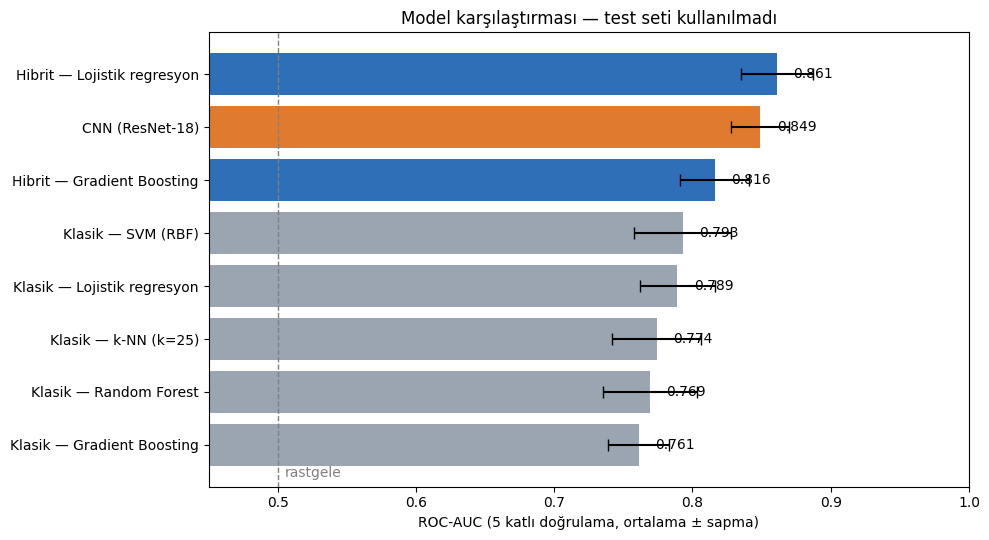

In [6]:
# ===== Adım 27: Klasik sınıflandırıcı karşılaştırması + hibrit model (yalnız 5 katlı doğrulama) =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

OZ_ADLAR = ["alan_mm2", "esdeger_cap_mm", "dairesellik", "doluluk", "eksantriklik",
            "ort_hu", "std_hu", "kalsifikasyon_orani", "kenar_gradyani"]
fold = df["fold"].values
F2 = pd.read_csv(f"{KOK}/ozellikler_v2.csv")
assert len(F2) == len(df)

# CNN'in doğrulama (OOF) skorları: her kat, kendisini görmeyen modelden
cnn = np.full(len(df), np.nan)
for k in range(5):
    p = np.load(f"{KOK}/oof/pencere_kat{k}.npy").astype(float).ravel()
    assert len(p) == (fold == k).sum(), f"kat {k}: uzunluk uyuşmuyor"
    cnn[fold == k] = p
gelistirme = fold != -1
if np.nanmin(cnn[gelistirme]) >= 0 and np.nanmax(cnn[gelistirme]) <= 1:   # olasılık -> logit
    cnn = np.log(np.clip(cnn, 1e-6, 1 - 1e-6) / (1 - np.clip(cnn, 1e-6, 1 - 1e-6)))

def hazir(model):    # eksik değer doldurma (yalnız eğitim katından) + ölçekleme + model
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

MODELLER = {
    "Lojistik regresyon": lambda: hazir(LogisticRegression(class_weight="balanced", max_iter=5000)),
    "SVM (RBF)":          lambda: hazir(SVC(kernel="rbf", C=1.0, class_weight="balanced")),
    "k-NN (k=25)":        lambda: hazir(KNeighborsClassifier(n_neighbors=25, weights="distance")),
    "Gradient Boosting":  lambda: hazir(HistGradientBoostingClassifier(class_weight="balanced",
                                         max_iter=300, learning_rate=0.05, random_state=42)),
    "Random Forest":      lambda: hazir(RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                         class_weight="balanced", random_state=42, n_jobs=-1)),
}

def skor(model, X, Xva):
    return model.decision_function(Xva) if hasattr(model, "decision_function") else model.predict_proba(Xva)[:, 1]

def cv(yapici, X):
    auc, pr = [], []
    for k in range(5):
        tr, va = gelistirme & (fold != k), fold == k
        m = yapici().fit(X[tr], y[tr])
        s = skor(m, X, X[va])
        auc.append(roc_auc_score(y[va], s)); pr.append(average_precision_score(y[va], s))
    return np.array(auc), np.array(pr)

X_klasik = F2[OZ_ADLAR].values
X_hibrit = np.column_stack([cnn, X_klasik])          # CNN skoru + 9 görüntü işleme özelliği

sonuc = {}
for ad, yap in MODELLER.items():
    sonuc[f"Klasik — {ad}"] = cv(yap, X_klasik)
# CNN tek başına (aynı OOF skorları, model eğitimi yok)
sonuc["CNN (ResNet-18)"] = (np.array([roc_auc_score(y[fold == k], cnn[fold == k]) for k in range(5)]),
                            np.array([average_precision_score(y[fold == k], cnn[fold == k]) for k in range(5)]))
sonuc["Hibrit — Lojistik regresyon"] = cv(MODELLER["Lojistik regresyon"], X_hibrit)
sonuc["Hibrit — Gradient Boosting"] = cv(MODELLER["Gradient Boosting"], X_hibrit)

tablo = pd.DataFrame({ad: {**{f"kat{k}": a[k] for k in range(5)},
                           "ROC-AUC": a.mean(), "± sapma": a.std(), "PR-AUC": p.mean()}
                      for ad, (a, p) in sonuc.items()}).T.round(3)
print(tablo.to_string())
tablo.to_csv(f"{KOK}/model_karsilastirma_cv.csv")

# Eşleştirilmiş karşılaştırmalar (aynı kat)
def fark(a, b):
    d = sonuc[a][0] - sonuc[b][0]
    print(f"{a}  −  {b}: {d.mean():+.3f}  (daha iyi olduğu kat: {(d > 0).sum()}/5)")
print()
for ad in MODELLER:
    if ad != "Random Forest":
        fark(f"Klasik — {ad}", "Klasik — Random Forest")
fark("Hibrit — Lojistik regresyon", "CNN (ResNet-18)")
fark("Hibrit — Gradient Boosting", "CNN (ResNet-18)")

# Sunum grafiği
fig, ax = plt.subplots(figsize=(10, 5.5))
sira = tablo.sort_values("ROC-AUC")
renk = ["#9AA5B1" if a.startswith("Klasik") else "#E07A2E" if a.startswith("CNN") else "#2E6FB7" for a in sira.index]
ax.barh(sira.index, sira["ROC-AUC"], xerr=sira["± sapma"], color=renk, capsize=4)
for i, v in enumerate(sira["ROC-AUC"]):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center")
ax.axvline(0.5, ls="--", c="gray", lw=1); ax.text(0.505, -0.6, "rastgele", color="gray")
ax.set_xlim(0.45, 1.0); ax.set_xlabel("ROC-AUC (5 katlı doğrulama, ortalama ± sapma)")
ax.set_title("Model karşılaştırması — test seti kullanılmadı")
plt.tight_layout(); plt.savefig(f"{KOK}/sunum_gorselleri/16_model_karsilastirma_tum.png", dpi=150); plt.show()

## Not — CNN modellerini yeniden yükleme
Adım 27'de sınıflandırıcı sözlüğüne de `MODELLER` adı verildiği için CNN listesi ezilmişti; bu hücre CNN modellerini yeniden yükler.

In [8]:
import glob, torch, torch.nn as nn, torchvision
MODELLER = []
for yol in sorted(glob.glob(f"{KOK}/modeller/pencere_kat*.pt")):
    m = torchvision.models.resnet18(weights=None); m.fc = nn.Linear(512, 1)
    sd = torch.load(yol, map_location="cpu")
    m.load_state_dict({k: v.float() for k, v in sd.items()})
    MODELLER.append(m.to(DEV).eval())
print("CNN modeli:", len(MODELLER))

CNN modeli: 5


## Adım 28 — Platt kalibrasyonu, doğrulamadan seçilen eşikler ve test setinde son ölçüm
Şeffaflık: test seti ilk kez Adım 22'de kullanıldı; bu ikinci ölçümdür. Bütün kararlar yalnız doğrulamayla verildi.

kontrol: yeniden hesaplanan test skoru ile kayıtlı skor farkı = 0.00008

=== TEST SETİ (1177 kayıt, 110 malign, 424 hasta) ===
                    Model  Test ROC-AUC      %95 GA  Test PR-AUC  Doğrulama ROC-AUC (OOF)
            CNN (kalibre)         0.891 0.841–0.933        0.533                    0.846
          Klasik (LR, v2)         0.844 0.800–0.889        0.430                    0.788
Hibrit (CNN + özellikler)         0.911 0.878–0.941        0.587                    0.858

=== Eşikler (doğrulamadan seçildi) ve testteki karşılıkları ===
                    Model           Eşik  değer  TP  FN  FP   TN  duyarlilik  ozgulluk  kesinlik    F1  dogruluk  doğr. duyarlılık  doğr. özgüllük
            CNN (kalibre)         Youden  0.072  98  12 274  793       0.891     0.743     0.263 0.407     0.757             0.789           0.753
            CNN (kalibre) %90 duyarlılık  0.038 105   5 534  533       0.955     0.500     0.164 0.280     0.542             0.901           0.560
       

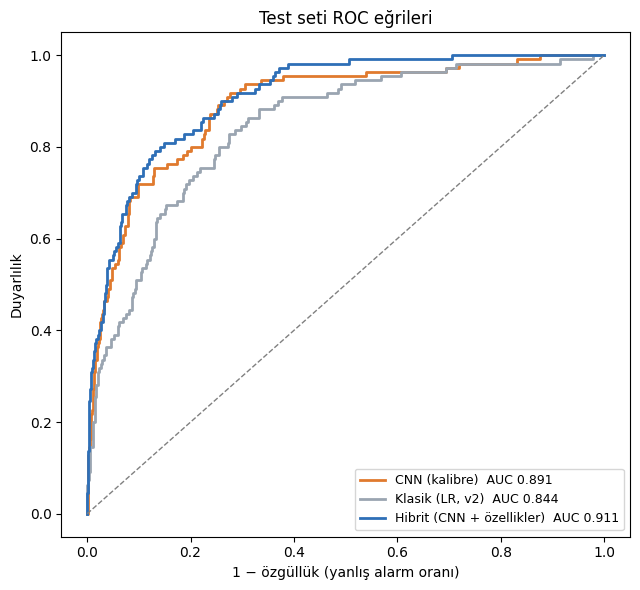


Not: Test seti ilk kez Adım 22'de kullanıldı; bu ikinci ölçümdür. v2 ve hibrit kararları yalnız doğrulamayla verildi.


In [9]:
# ===== Adım 28: Kalibrasyon, eşikler ve test setinde son ölçüm =====
# Bütün kararlar bu hücreden ÖNCE verildi (Adım 26-27). Test seti burada bir kez kullanılır.
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

assert "MODELLER" in globals() and "hazirla" in globals(), "Önce demo hücresini çalıştır (modeller yüklü olmalı)."
OZ_ADLAR = ["alan_mm2", "esdeger_cap_mm", "dairesellik", "doluluk", "eksantriklik",
            "ort_hu", "std_hu", "kalsifikasyon_orani", "kenar_gradyani"]
fold = df["fold"].values; gel = fold != -1; tst = fold == -1
hasta = df["PatientID"].values
Xk = pd.read_csv(f"{KOK}/ozellikler_v2.csv")[OZ_ADLAR].values

def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def sigm(z): return 1 / (1 + np.exp(-z))

# ---------- 1) CNN skorları: OOF (doğrulama) ve her kat modelinin test logiti ----------
cnn_oof = np.full(len(df), np.nan)
for k in range(5):
    cnn_oof[fold == k] = np.load(f"{KOK}/oof/pencere_kat{k}.npy").astype(float).ravel()
if np.nanmin(cnn_oof[gel]) >= 0 and np.nanmax(cnn_oof[gel]) <= 1:
    cnn_oof = logit(cnn_oof)
test_idx = np.where(tst)[0]
test_logit = np.zeros((len(MODELLER), len(test_idx)))   # (5 model, test)
with torch.no_grad():
    for b in range(0, len(test_idx), 64):
        x = hazirla(test_idx[b:b + 64], NORM)
        for j, m in enumerate(MODELLER):
            test_logit[j, b:b + 64] = m(x).squeeze(1).float().cpu().numpy()
ref = np.load(f"{KOK}/test_tahmin_cnn.npy").astype(float).ravel()
print(f"kontrol: yeniden hesaplanan test skoru ile kayıtlı skor farkı = {np.abs(sigm(test_logit).mean(0) - ref).mean():.5f}")

# ---------- 2) Modeller: hepsi yalnız geliştirme verisiyle eğitilir ----------
def lr(): return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(class_weight="balanced", max_iter=5000))
def oof_tahmin(X):                     # eşik seçimi için doğrulama tahminleri
    p = np.full(len(df), np.nan)
    for k in range(5):
        tr, va = gel & (fold != k), fold == k
        p[va] = lr().fit(X[tr], y[tr]).predict_proba(X[va])[:, 1]
    return p

# a) CNN + Platt kalibrasyonu (OOF logitlerinden öğrenilir, sıralamayı değiştirmez)
platt = LogisticRegression(C=1e6, max_iter=5000).fit(cnn_oof[gel, None], y[gel])
kal = lambda z: platt.predict_proba(np.asarray(z).reshape(-1, 1))[:, 1]
p_oof = {"CNN (kalibre)": np.where(gel, kal(np.nan_to_num(cnn_oof)), np.nan)}
p_test = {"CNN (kalibre)": np.mean([kal(z) for z in test_logit], axis=0)}

# b) Klasik: lojistik regresyon, v2 özellikleri (Adım 27 kuralıyla seçildi)
p_oof["Klasik (LR, v2)"] = oof_tahmin(Xk)
p_test["Klasik (LR, v2)"] = lr().fit(Xk[gel], y[gel]).predict_proba(Xk[tst])[:, 1]

# c) Hibrit: CNN logiti + 9 özellik -> lojistik regresyon (Adım 27 kuralıyla seçildi)
Xh = np.column_stack([cnn_oof, Xk])
p_oof["Hibrit (CNN + özellikler)"] = oof_tahmin(Xh)
hib = lr().fit(Xh[gel], y[gel])
p_test["Hibrit (CNN + özellikler)"] = np.mean(
    [hib.predict_proba(np.column_stack([z, Xk[tst]]))[:, 1] for z in test_logit], axis=0)

# ---------- 3) Eşikler: yalnız doğrulama tahminlerinden ----------
def esikler(yv, pv):
    fpr, tpr, th = roc_curve(yv, pv)
    youden = th[np.argmax(tpr - fpr)]
    duy90 = th[np.argmax(tpr >= 0.90)]
    aday = np.unique(np.quantile(pv, np.linspace(0.5, 0.995, 400)))
    f1 = [2 * ((pv >= t) & (yv == 1)).sum() / ((pv >= t).sum() + (yv == 1).sum()) for t in aday]
    return {"Youden": youden, "%90 duyarlılık": duy90, "F1-maks": aday[int(np.argmax(f1))]}

def olc(yt, pt, t):
    tah = pt >= t
    TP = int((tah & (yt == 1)).sum()); FN = int((~tah & (yt == 1)).sum())
    FP = int((tah & (yt == 0)).sum()); TN = int((~tah & (yt == 0)).sum())
    duy, ozg = TP / (TP + FN), TN / (TN + FP)
    kes = TP / (TP + FP) if TP + FP else 0.0
    return dict(TP=TP, FN=FN, FP=FP, TN=TN, duyarlilik=duy, ozgulluk=ozg, kesinlik=kes,
                F1=2 * kes * duy / (kes + duy) if kes + duy else 0.0, dogruluk=(TP + TN) / len(yt))

# ---------- 4) Test sonuçları + hasta düzeyinde bootstrap ----------
rng = np.random.default_rng(0)
yt = y[tst]; ht = hasta[tst]
hastalar = np.unique(ht); satirlar = {h: np.where(ht == h)[0] for h in hastalar}
ornekler = [np.concatenate([satirlar[h] for h in rng.choice(hastalar, len(hastalar))]) for _ in range(1000)]
def ga(p):
    v = [roc_auc_score(yt[o], p[o]) for o in ornekler if 0 < yt[o].sum() < len(o)]
    return np.percentile(v, [2.5, 97.5])

ozet, esik_tablo = [], []
for ad in p_test:
    pv, pt = p_oof[ad][gel], p_test[ad]
    lo, hi = ga(pt)
    ozet.append({"Model": ad, "Test ROC-AUC": roc_auc_score(yt, pt), "%95 GA": f"{lo:.3f}–{hi:.3f}",
                 "Test PR-AUC": average_precision_score(yt, pt),
                 "Doğrulama ROC-AUC (OOF)": roc_auc_score(y[gel], pv)})
    for e_ad, t in esikler(y[gel], pv).items():
        dv = olc(y[gel], pv, t)
        esik_tablo.append({"Model": ad, "Eşik": e_ad, "değer": t, **olc(yt, pt, t),
                           "doğr. duyarlılık": dv["duyarlilik"], "doğr. özgüllük": dv["ozgulluk"]})
ozet = pd.DataFrame(ozet).round(3); esik_tablo = pd.DataFrame(esik_tablo).round(3)
print(f"\n=== TEST SETİ ({tst.sum()} kayıt, {int(y[tst].sum())} malign, {len(hastalar)} hasta) ===")
print(ozet.to_string(index=False))
print("\n=== Eşikler (doğrulamadan seçildi) ve testteki karşılıkları ===")
print(esik_tablo.to_string(index=False))

# Hibrit − CNN farkı (aynı bootstrap örnekleri, eşleştirilmiş)
d = [roc_auc_score(yt[o], p_test["Hibrit (CNN + özellikler)"][o]) - roc_auc_score(yt[o], p_test["CNN (kalibre)"][o])
     for o in ornekler if 0 < yt[o].sum() < len(o)]
print(f"\nHibrit − CNN test AUC farkı: {np.mean(d):+.3f}  (%95 GA {np.percentile(d, 2.5):+.3f} – {np.percentile(d, 97.5):+.3f})")

ozet.to_csv(f"{KOK}/test_sonuclari_v2.csv", index=False)
esik_tablo.to_csv(f"{KOK}/test_esikler_v2.csv", index=False)
np.savez(f"{KOK}/test_tahminleri_v2.npz", **{k.split(" ")[0]: v for k, v in p_test.items()}, test_logit=test_logit)
import pickle
pickle.dump({"platt": platt, "hibrit": hib, "klasik": lr().fit(Xk[gel], y[gel]),
             "esikler": {ad: esikler(y[gel], p_oof[ad][gel]) for ad in p_oof}},
            open(f"{KOK}/demo_modelleri.pkl", "wb"))

# ROC grafiği
fig, ax = plt.subplots(figsize=(6.5, 6))
for ad, renk in zip(p_test, ["#E07A2E", "#9AA5B1", "#2E6FB7"]):
    f, t, _ = roc_curve(yt, p_test[ad])
    ax.plot(f, t, color=renk, lw=2, label=f"{ad}  AUC {roc_auc_score(yt, p_test[ad]):.3f}")
ax.plot([0, 1], [0, 1], "--", c="gray", lw=1)
ax.set_xlabel("1 − özgüllük (yanlış alarm oranı)"); ax.set_ylabel("Duyarlılık")
ax.set_title("Test seti ROC eğrileri"); ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(f"{KOK}/sunum_gorselleri/17_test_roc_v2.png", dpi=150); plt.show()
print("\nNot: Test seti ilk kez Adım 22'de kullanıldı; bu ikinci ölçümdür. v2 ve hibrit kararları yalnız doğrulamayla verildi.")

## Demo v2 — Bölütleme v2, üç model ve karar satırı

In [10]:
# ===== Demo v2: bölütleme v2 + üç model + karar satırı =====
# Gerekenler (bu oturumda çalışmış olmalı): demo hücresi (X_p, X_c, df, y, MODELLER, hazirla, NORM, gradcam)
# ve Adım 26 (hu2k, KATI, BUZLU, KENAR, R2, morf, kapama_hizli, bolutle_v1, ozellik_cikar, OZ_ADLAR).
import pickle, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, gradio as gr
from scipy import ndimage
from skimage.morphology import disk
from skimage.segmentation import watershed

for ad in ["X_p", "X_c", "MODELLER", "hazirla", "gradcam", "ozellik_cikar", "bolutle_v1", "kapama_hizli"]:
    assert ad in globals(), f"{ad} yok: önce demo hücresini ve Adım 26'yı çalıştır."
assert not isinstance(MODELLER, dict), "MODELLER CNN listesi olmalı: CNN modellerini yeniden yükle."

DM = pickle.load(open(f"{KOK}/demo_modelleri.pkl", "rb"))
ESIK = DM["esikler"]              # {"CNN (kalibre)": {"Youden":..,"%90 duyarlılık":..,"F1-maks":..}, ...}
test_idx = np.where(df["fold"].values == -1)[0]


def bolutle_tek(k, esik=KATI, maks_r=40, ayrinti=False):
    """Adım 26'daki v2 ile aynı; ek olarak ara adımları (doku, akciğer, kapanmış akciğer) döndürür."""
    bos = np.zeros(k.shape, bool)
    doku = k > esik
    hava = ndimage.binary_opening(~doku, structure=disk(1))
    lab, n = ndimage.label(hava)
    bilgi = {"r": None, "doku": doku, "akc": bos, "ic": bos, "tohum": None}
    if n == 0:
        return (bos, bilgi) if ayrinti else bos
    alan = ndimage.sum(hava, lab, range(1, n + 1))
    kenarda = [l for l in np.unique(lab[KENAR & hava]) if l > 0 and alan[l - 1] >= 200]
    akc_kenar = np.isin(lab, kenarda)
    akc_hepsi = np.isin(lab, 1 + np.where(alan >= 200)[0])
    bilgi["akc"] = akc_kenar if akc_kenar.any() else akc_hepsi
    aday = doku & (R2 <= 36)
    if not aday.any():
        return (bos, bilgi) if ayrinti else bos
    yy, xx = np.nonzero(aday)
    j = np.argmin(R2[yy, xx]); ty, tx = yy[j], xx[j]
    bilgi["tohum"] = (ty, tx)
    r_sec, ic = None, np.ones_like(doku)
    for akc in (akc_kenar, akc_hepsi):
        if not akc.any():
            continue
        for r in range(2, maks_r + 1, 2):
            aday_ic = ndimage.binary_fill_holes(kapama_hizli(akc, r))
            if aday_ic[ty, tx]:
                r_sec, ic = r, aday_ic
                bilgi["akc"] = akc
                break
        if r_sec is not None:
            break
    bilgi["r"], bilgi["ic"] = r_sec, ic
    nod = ndimage.binary_fill_holes(doku & ic)
    nod = morf(nod, ndimage.binary_opening, 1)
    lab2, _ = ndimage.label(nod)
    if lab2[ty, tx] == 0:
        yy, xx = np.nonzero(nod)
        if len(yy) == 0:
            return (bos, bilgi) if ayrinti else bos
        j = np.argmin(R2[yy, xx]); ty, tx = yy[j], xx[j]
    bil = lab2 == lab2[ty, tx]
    dist = ndimage.distance_transform_edt(bil)
    isaret = np.zeros(k.shape, int)
    isaret[ty, tx] = 1
    cevre = bil & (R2 <= 100)
    if cevre.any():
        cy, cx = np.unravel_index(np.argmax(np.where(cevre, dist, -1)), dist.shape)
        isaret[cy, cx] = 1
        rn = dist[cy, cx]
    else:
        rn = dist[ty, tx]
    isaret[bil & (((YY - ty) ** 2 + (XX - tx) ** 2) > (3 * rn + 6) ** 2)] = 2
    isaret[KENAR & bil] = 2
    sonuc = ndimage.binary_fill_holes(watershed(-dist, isaret, mask=bil) == 1)
    return (sonuc, bilgi) if ayrinti else sonuc


def bolutle_v2(k, ayrinti=False):
    m, bilgi = bolutle_tek(k, KATI, ayrinti=True)
    bilgi["tur"] = "katı"
    if m.sum() < 8:
        m2, b2 = bolutle_tek(k, BUZLU, ayrinti=True)
        if m2.sum() > m.sum():
            m, bilgi = m2, b2
            bilgi["tur"] = "buzlu cam"
    return (m, bilgi) if ayrinti else m


@torch.no_grad()
def cnn_logitleri(idx):
    x = hazirla(np.atleast_1d(idx), NORM)
    return np.stack([m(x).squeeze(1).float().cpu().numpy() for m in MODELLER])   # (5, n)


def olasiliklar(idx, ozellik):
    z = cnn_logitleri(idx)[:, 0]                                              # 5 modelin logiti
    f = np.array([[ozellik[a] for a in OZ_ADLAR]])
    p_cnn = np.mean([DM["platt"].predict_proba([[v]])[0, 1] for v in z])
    p_kla = DM["klasik"].predict_proba(f)[0, 1]
    p_hib = np.mean([DM["hibrit"].predict_proba(np.column_stack([[v], f]))[0, 1] for v in z])
    return {"Klasik (LR, v2)": p_kla, "CNN (kalibre)": p_cnn, "Hibrit (CNN + özellikler)": p_hib}


# Kendini kontrol: demo, Adım 28'de raporlanan test tahminlerini yeniden üretiyor mu?
_ref = np.load(f"{KOK}/test_tahminleri_v2.npz")
_fark = []
for s in range(15):
    i = test_idx[s]; k = np.asarray(X_p[i, 1], dtype=np.float32) / 255.
    p = olasiliklar(i, ozellik_cikar(k, bolutle_v2(k)))
    _fark.append([abs(p["Klasik (LR, v2)"] - _ref["Klasik"][s]), abs(p["CNN (kalibre)"] - _ref["CNN"][s]),
                  abs(p["Hibrit (CNN + özellikler)"] - _ref["Hibrit"][s])])
print("kontrol (klasik, CNN, hibrit) en büyük fark:", np.round(np.max(_fark, axis=0), 5))


def analiz(sira):
    idx = int(test_idx[int(sira)])
    k = np.asarray(X_p[idx, 1], dtype=np.float32) / 255.
    maske, b = bolutle_v2(k, ayrinti=True)
    eski = bolutle_v1(k)
    oz = ozellik_cikar(k, maske)
    p = olasiliklar(idx, oz)
    cam = gradcam(hazirla(np.array([idx]), NORM))

    fig, ax = plt.subplots(2, 4, figsize=(16, 8.4))
    ax = ax.ravel()
    ax[0].imshow(k, cmap="gray", vmin=0, vmax=1); ax[0].set_title("1. HU pencereleme (−1350…150)")
    ax[1].imshow(X_c[idx, 1], cmap="gray"); ax[1].set_title("2. CLAHE (yalnız görsel)")
    ax[2].imshow(b["doku"], cmap="gray"); ax[2].set_title(f"3. Eşikleme ({'−400' if b['tur']=='katı' else '−750'} HU)")
    ax[3].imshow(b["akc"], cmap="gray"); ax[3].set_title("4. Akciğer maskesi")
    ax[4].imshow(k, cmap="gray", vmin=0, vmax=1)
    if b["ic"].any(): ax[4].contour(b["ic"], levels=[.5], colors="cyan", linewidths=1.2)
    if b["tohum"]: ax[4].plot(b["tohum"][1], b["tohum"][0], "r+", ms=12, mew=2)
    ax[4].set_title(f"5. Yuvarlanan top kapama (r={b['r']})")
    ax[5].imshow(k, cmap="gray", vmin=0, vmax=1)
    if eski.any(): ax[5].contour(eski, levels=[.5], colors="red", linewidths=1, linestyles="dashed")
    if maske.any(): ax[5].contour(maske, levels=[.5], colors="lime", linewidths=1.8)
    ax[5].set_title("6. Nodül: v2 (yeşil), v1 (kırmızı)")
    ax[6].imshow(k, cmap="gray", vmin=0, vmax=1); ax[6].imshow(cam, cmap="jet", alpha=0.45)
    ax[6].set_title("7. Grad-CAM (CNN nereye baktı)")
    ax[7].hist(np.ravel(X_p[idx, 1]), 64, alpha=.6, label="pencere")
    ax[7].hist(np.ravel(X_c[idx, 1]), 64, alpha=.6, label="CLAHE")
    ax[7].legend(); ax[7].set_title("8. Histogram")
    for a in ax[:7]: a.axis("off")
    fig.tight_layout(); plt.close(fig)

    gercek = int(y[idx])
    def karar(ad, esik_adi):
        t = ESIK[ad][esik_adi]; m = p[ad] >= t
        dogru = "✓ doğru" if int(m) == gercek else "✗ yanlış"
        return f"{'**MALİGN**' if m else 'benign'} ({dogru}, eşik {t:.2f})"
    satirlar = "\n".join(f"| {ad} | {p[ad]:.3f} | {karar(ad, '%90 duyarlılık')} | {karar(ad, 'Youden')} |" for ad in p)
    md = (f"### Test nodülü #{int(sira)} (satır {idx}) — gerçek etiket: "
          f"{'**MALİGN**' if gercek else 'benign'}\n\n"
          f"| Model | Malignite olasılığı | Karar: tarama eşiği (%90 duyarlılık) | Karar: dengeli eşik (Youden) |\n"
          f"|---|---|---|---|\n{satirlar}\n\n"
          f"**Bölütleme:** {b['tur']} doku eşiği, kapama yarıçapı r = {b['r']} "
          f"({'duvara yapışık olabilir' if (b['r'] or 0) > 2 else 'yalıtılmış nodül'})  \n"
          f"**Özellikler:** çap {oz['esdeger_cap_mm']:.1f} mm · dairesellik {oz['dairesellik']:.2f} · "
          f"doluluk {oz['doluluk']:.2f} · ort. HU {oz['ort_hu']:.0f} · kenar gradyanı {oz['kenar_gradyani']:.3f}\n\n"
          f"<sub>Eşikler yalnız doğrulama verisinden seçildi. Bu araç bir araştırma prototipidir, tanı aracı değildir.</sub>")
    return fig, md


rng = np.random.default_rng()
def rastgele(sinif):
    return int(rng.choice(np.where(y[test_idx] == sinif)[0]))

with gr.Blocks(title="Akciğer Nodülü Malignite Analizi") as demo:
    gr.Markdown("# BT Görüntülerinde Akciğer Nodülü Malignite Analizi\n"
                "LUNA25 test seti (modellerin hiç görmediği 1177 görüntü) · klasik görüntü işleme, CNN ve hibrit model")
    with gr.Row():
        sira = gr.Slider(0, len(test_idx) - 1, step=1, value=0, label="Test nodülü sırası")
        b_m = gr.Button("Rastgele malign"); b_b = gr.Button("Rastgele benign")
        b_a = gr.Button("Analiz et", variant="primary")
    md = gr.Markdown()
    cizim = gr.Plot()
    b_a.click(analiz, sira, [cizim, md])
    b_m.click(lambda: rastgele(1), None, sira).then(analiz, sira, [cizim, md])
    b_b.click(lambda: rastgele(0), None, sira).then(analiz, sira, [cizim, md])

demo.launch(share=True, debug=False)

kontrol (klasik, CNN, hibrit) en büyük fark: [0. 0. 0.]
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://514d7c26fa4bc7862f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Demo v2 — Grad-CAM kararın yönünde (malign/benign kanıtı)

In [11]:
# Grad-CAM'i kararın yönünde hesapla: malign derse malign kanıtı, benign derse benign kanıtı
GC_YON = {"yon": 1}
def gradcam(x):
    haritalar, logitler = [], []
    for m in MODELLER:
        akt = {}
        h = m.layer4[-1].register_forward_hook(lambda mod, i, o: akt.__setitem__("a", o))
        with torch.enable_grad():
            cikti = m(x)
            logitler.append(float(cikti.sum()))
            yon = GC_YON["yon"]
            g = torch.autograd.grad(yon * cikti.sum(), akt["a"])[0]
        h.remove()
        w = g.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * akt["a"]).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=128, mode="bilinear", align_corners=False)[0, 0]
        haritalar.append((cam / (cam.max() + 1e-8)).cpu().numpy())
    return np.mean(haritalar, axis=0)

def analiz_yonlu(sira):
    idx = int(test_idx[int(sira)])
    p_cnn = np.mean([DM["platt"].predict_proba([[v]])[0, 1] for v in cnn_logitleri(idx)[:, 0]])
    malign_mi = p_cnn >= ESIK["CNN (kalibre)"]["Youden"]
    GC_YON["yon"] = 1 if malign_mi else -1
    fig, md = analiz(sira)
    fig.axes[6].set_title(f"7. Grad-CAM: {'malign' if malign_mi else 'benign'} kanıtı nerede?")
    return fig, md

with gr.Blocks(title="Akciğer Nodülü Malignite Analizi") as demo:
    gr.Markdown("# BT Görüntülerinde Akciğer Nodülü Malignite Analizi\n"
                "LUNA25 test seti (modellerin hiç görmediği 1177 görüntü) · klasik görüntü işleme, CNN ve hibrit model")
    with gr.Row():
        sira = gr.Slider(0, len(test_idx) - 1, step=1, value=0, label="Test nodülü sırası")
        b_m = gr.Button("Rastgele malign"); b_b = gr.Button("Rastgele benign")
        b_a = gr.Button("Analiz et", variant="primary")
    md = gr.Markdown()
    cizim = gr.Plot()
    b_a.click(analiz_yonlu, sira, [cizim, md])
    b_m.click(lambda: rastgele(1), None, sira).then(analiz_yonlu, sira, [cizim, md])
    b_b.click(lambda: rastgele(0), None, sira).then(analiz_yonlu, sira, [cizim, md])
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://97af2bf93204a7e577.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Demo örneklerini kategorilere ayırma

In [12]:
r = np.load(f"{KOK}/test_tahminleri_v2.npz"); yt = y[test_idx]
t = {"k": ESIK["Klasik (LR, v2)"]["Youden"], "c": ESIK["CNN (kalibre)"]["Youden"], "h": ESIK["Hibrit (CNN + özellikler)"]["Youden"]}
K_, C_, H_ = r["Klasik"] >= t["k"], r["CNN"] >= t["c"], r["Hibrit"] >= t["h"]
dogru = lambda tah: tah == (yt == 1)
gruplar = {
    "Malign, üç model de doğru (en güvenli demo)": (yt == 1) & dogru(K_) & dogru(C_) & dogru(H_),
    "Hibrit doğru, CNN yanlış (hibritin katkısı)":  dogru(H_) & ~dogru(C_),
    "CNN doğru, klasik yanlış (CNN'in katkısı)":     dogru(C_) & ~dogru(K_),
    "Malign, üç model de yanlış (sınırlılık örneği)": (yt == 1) & ~dogru(K_) & ~dogru(C_) & ~dogru(H_),
}
for ad, m in gruplar.items():
    s = np.where(m)[0]
    print(f"{ad}: {len(s)} örnek → sıra no: {s[:12].tolist()}")

Malign, üç model de doğru (en güvenli demo): 77 örnek → sıra no: [0, 3, 4, 5, 7, 8, 10, 11, 12, 13, 15, 16]
Hibrit doğru, CNN yanlış (hibritin katkısı): 134 örnek → sıra no: [46, 55, 61, 63, 64, 65, 68, 71, 74, 75, 86, 88]
CNN doğru, klasik yanlış (CNN'in katkısı): 185 örnek → sıra no: [1, 2, 30, 48, 51, 57, 70, 84, 100, 101, 125, 126]
Malign, üç model de yanlış (sınırlılık örneği): 3 örnek → sıra no: [9, 662, 664]


## Seçilen demo örneklerini görsel olarak kaydetme

In [13]:
import os
klasor = f"{KOK}/sunum_gorselleri/demo_ornekleri"; os.makedirs(klasor, exist_ok=True)
ornekler = {0: "1_malign_hepsi_dogru", 46: "2_hibrit_duzeltiyor",
            1: "3_cnn_klasigi_geciyor", 9: "4_hepsi_yanlis"}
for sira, ad in ornekler.items():
    fig, md = analiz_yonlu(sira)
    fig.savefig(f"{klasor}/{ad}_sira{sira}.png", dpi=150, bbox_inches="tight")
    open(f"{klasor}/{ad}_sira{sira}.md", "w").write(md)
    print("kaydedildi:", ad, "| sıra", sira)
    display(fig)

Output hidden; open in https://colab.research.google.com to view.